# 4. La transparence des développeurs : Stanford et l'AI Act

Deux sources complètent la mesure d'opacité construite à partir d'Epoch (notebook 1) :

- le **Foundation Model Transparency Index** (Stanford) : une centaine d'indicateurs notés 0/1 pour les grands développeurs, en octobre 2023, mai 2024 et décembre 2025 ;
- la liste officielle des **signataires du code de bonnes pratiques** européen, qui accompagne les obligations de l'AI Act en vigueur depuis le 2 août 2025.

**Questions**
1. La transparence des grands développeurs progresse-t-elle ou recule-t-elle entre 2023 et 2025 ?
2. Les deux mesures de l'opacité (Stanford, Epoch) racontent-elles la même histoire ?
3. Les signataires du code publient-ils davantage depuis août 2025 que les non-signataires ?

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import FIGURES
from style import appliquer_style
from nettoyage import charger_dernier, preparer_epoch, cle_organisation, statut_signature
appliquer_style()
FIGURES.mkdir(exist_ok=True)


## 0. Chargement

In [2]:
fmti = charger_dernier("fmti_scores")
signataires = charger_dernier("signataires_code")
epoch = preparer_epoch(charger_dernier("epoch_notable_models"))
print(fmti.groupby("edition")["developpeur"].nunique())
print(f"{len(signataires)} signataires, dont partiels :", signataires.loc[signataires['signature'] != 'complète', 'organisation'].tolist())

Lecture locale : data/raw/fmti_scores_2026-11-22.csv
Lecture locale : data/raw/signataires_code_2026-11-22.csv
Lecture locale : data/raw/epoch_notable_models_2026-11-22.csv
edition
2023-10    10
2024-05    14
2025-12    13
Name: developpeur, dtype: int64
23 signataires, dont partiels : ['xAI']


## 1. Le score de transparence de Stanford

Score = part des indicateurs satisfaits. **La grille a changé en 2025** : une baisse entre 2024 et 2025 peut venir d'indicateurs plus exigeants, pas seulement d'un recul réel. On compare donc surtout les développeurs **entre eux** au sein d'une même édition, et on interprète l'évolution avec prudence.

In [3]:
score = (fmti.assign(cle=fmti["developpeur"].map(cle_organisation).fillna(fmti["developpeur"]))
         .groupby(["cle", "edition"])["satisfait"].mean().unstack())
score["statut"] = [statut_signature(c, signataires) for c in score.index]
score.sort_values(score.columns[-2], ascending=False).style.format(
    {c: "{:.0%}" for c in score.columns if c != "statut"}, na_rep="—")

edition,2023-10,2024-05,2025-12,statut
cle,,,,
IBM,—,64%,95%,complète
Writer,—,56%,72%,complète
AI21 Labs,25%,75%,66%,non signataire
Anthropic,36%,51%,46%,complète
Google,40%,47%,41%,complète
Amazon,12%,41%,39%,complète
OpenAI,48%,49%,35%,complète
DeepSeek,—,—,32%,non signataire
Meta,54%,60%,31%,non signataire


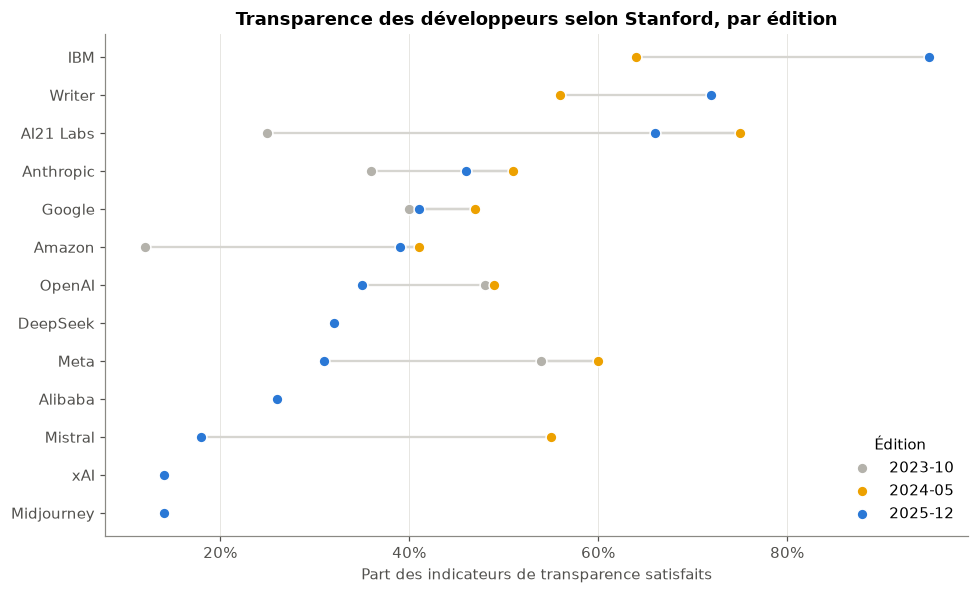

In [4]:
editions = [c for c in score.columns if c != "statut"]
present = score.dropna(subset=editions[-1:]).sort_values(editions[-1])

fig, ax = plt.subplots(figsize=(9, 5.5))
couleurs_ed = ["#b4b2ab", "#eda100", "#2a78d6"]
for ed, c in zip(editions, couleurs_ed):
    ax.scatter(present[ed], present.index, color=c, s=50, label=ed, zorder=3, edgecolor="white")
for nom, ligne in present[editions].iterrows():
    v = ligne.dropna()
    ax.plot(v.values, [nom] * len(v), color="#d6d5d0", lw=1.5, zorder=1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Part des indicateurs de transparence satisfaits")
ax.set_title("Transparence des développeurs selon Stanford, par édition")
ax.legend(title="Édition", loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "30_fmti.png")

**Interprétation.** En 2025, IBM (95 %) et Writer (72 %) sont de loin les plus transparents, devant AI21 Labs, Anthropic et Google. Mistral est parmi les moins transparents avec 18 %, au niveau de xAI et Midjourney (14 %). Les développeurs de modèles ouverts, comme Meta (31 %), DeepSeek (32 %) et Alibaba (26 %), sont dans la moitié basse du classement. Pour Stanford, ouvert ne veut donc pas dire transparent, ce qui rejoint le résultat B.2 du notebook 1. La baisse de Meta (60 % puis 31 %) et de Mistral (55 % puis 18 %) entre 2024 et 2025 vient en partie du changement de grille.

## 2. Les deux mesures concordent-elles ?

Pour chaque développeur présent dans les deux sources : score Stanford 2025 contre score de transparence moyen de ses modèles récents dans Epoch (de 0 à 5 informations connues). Si les deux mesuraient la même chose, les développeurs bien notés par Stanford auraient aussi les meilleurs scores Epoch.

In [5]:
epoch["cle"] = epoch["Organization"].map(cle_organisation)
epoch_recent = (epoch.loc[epoch["annee"] >= 2024].dropna(subset=["cle"])
                .groupby("cle")["score_transparence"].agg(["mean", "count"]))
validation = score[[editions[-1]]].join(epoch_recent, how="inner").dropna()
validation.columns = ["stanford_2025", "epoch_score_moyen", "modeles_epoch"]
print(f"{len(validation)} développeurs présents dans les deux sources")
validation.sort_values("stanford_2025", ascending=False).round(2)

11 développeurs présents dans les deux sources


,stanford_2025,epoch_score_moyen,modeles_epoch
cle,,,
Writer,0.72,1.00,2
AI21 Labs,0.66,2.00,1
Anthropic,0.46,0.14,22
Google,0.41,0.67,33
Amazon,0.39,2.50,2
OpenAI,0.35,0.23,52
DeepSeek,0.32,3.10,10
Meta,0.31,2.12,16
Alibaba,0.26,1.72,29


**Interprétation.** Les deux mesures ne concordent pas. Anthropic et OpenAI sont plutôt bien notés par Stanford (46 % et 35 %) mais ont le score Epoch le plus bas (0,14 et 0,23 information sur 5). À l'inverse, DeepSeek et Meta sont mal notés par Stanford (32 % et 31 %) mais ont les meilleurs scores Epoch (3,1 et 2,1). Cela s'explique par ce que mesure chaque source. Stanford note ce que le développeur divulgue lui-même, y compris sur les usages et la gouvernance, alors qu'Epoch note ce qui est connu du modèle, y compris ce qu'on peut mesurer soi-même sur un modèle ouvert. Writer, AI21 Labs et Amazon n'ont qu'un ou deux modèles dans Epoch, leur position compte donc peu.

Variante plus stricte : on ne compte la puissance de calcul comme publiée que si elle a été **calculée depuis des informations publiées**, pas devinée par Epoch (voir notebook 1, B.1 bis).

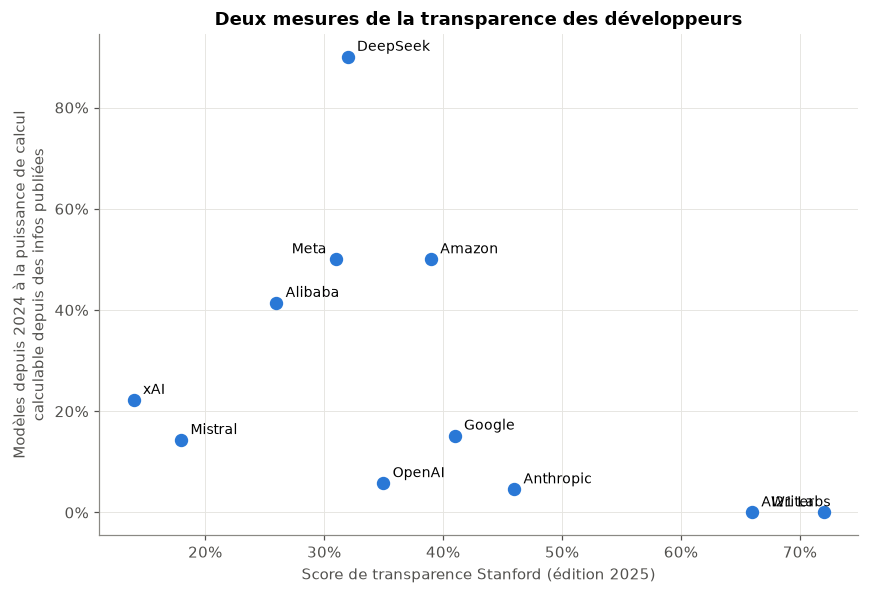

,stanford_2025,epoch_score_moyen,modeles_epoch,epoch_calcul_strict
cle,,,,
AI21 Labs,0.66,2.00,1,0.00
Alibaba,0.26,1.72,29,0.41
Amazon,0.39,2.50,2,0.50
Anthropic,0.46,0.14,22,0.05
DeepSeek,0.32,3.10,10,0.90
Google,0.41,0.67,33,0.15
Meta,0.31,2.12,16,0.50
Mistral,0.18,1.29,7,0.14
OpenAI,0.35,0.23,52,0.06


In [6]:
from graphiques import nuage_de_points_annote

epoch_strict = (epoch.loc[epoch["annee"] >= 2024].dropna(subset=["cle"])
                .assign(calcul_strict=lambda d: d["source_calcul"] == "calculée depuis des infos publiées")
                .groupby("cle")["calcul_strict"].mean())
validation["epoch_calcul_strict"] = epoch_strict.reindex(validation.index)
nuage_de_points_annote(validation, "stanford_2025", "epoch_calcul_strict",
                       "Deux mesures de la transparence des développeurs",
                       "Score de transparence Stanford (édition 2025)",
                       "Modèles depuis 2024 à la puissance de calcul\ncalculable depuis des infos publiées")
plt.show()
validation.round(2)

## 3. Avant / après l'AI Act, signataires contre non-signataires

On compare, pour les modèles publiés depuis janvier 2024, la part qui publie sa puissance de calcul et ses données d'entraînement, avant et après le 2 août 2025, selon que le développeur a signé le code européen.

C'est une **comparaison descriptive** du type « différence de différences », pas une estimation causale : peu de modèles après août 2025, des signataires qui n'ont pas été tirés au hasard, et un AI Act qui concerne en principe tous les fournisseurs actifs dans l'UE, signataires ou non.

In [7]:
recent = epoch.loc[epoch["date"] >= "2024-01-01"].copy()
recent["statut"] = recent["cle"].map(lambda c: statut_signature(c, signataires))
recent["groupe"] = np.where(recent["statut"].str.startswith("complète"), "signataire",
                   np.where(recent["statut"] == "non signataire", "non signataire", "autre"))
recent = recent.loc[recent["groupe"] != "autre"]
recent["periode"] = np.where(recent["apres_ai_act"], "après août 2025", "avant août 2025")

tableau = (recent.groupby(["groupe", "periode"])
           .agg(modeles=("Model", "count"), publie_calcul=("publie_calcul", "mean"),
                publie_donnees=("publie_donnees", "mean"), score=("score_transparence", "mean"))
           .reindex(pd.MultiIndex.from_product([["signataire", "non signataire"],
                                                ["avant août 2025", "après août 2025"]])))
tableau.style.format({"publie_calcul": "{:.0%}", "publie_donnees": "{:.0%}", "score": "{:.2f}"})

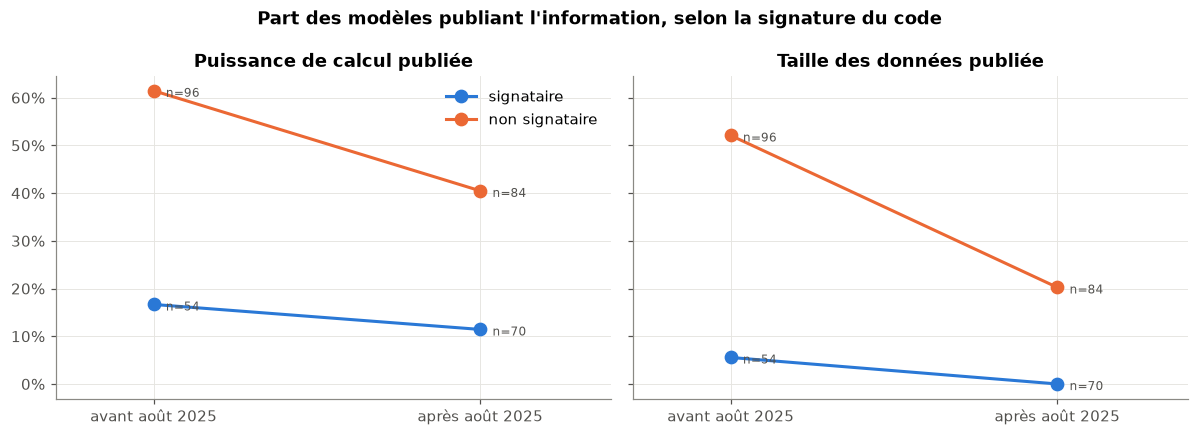

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, var, titre in zip(axes, ["publie_calcul", "publie_donnees"],
                          ["Puissance de calcul publiée", "Taille des données publiée"]):
    for g, c in [("signataire", "#2a78d6"), ("non signataire", "#eb6834")]:
        v = tableau.loc[g, var]
        ax.plot([0, 1], v.values, marker="o", markersize=8, color=c, label=g)
        for xi, yi, n in zip([0, 1], v.values, tableau.loc[g, "modeles"]):
            ax.annotate(f"n={n:.0f}", (xi, yi), textcoords="offset points", xytext=(8, -4),
                        fontsize=8, color="#52514e")
    ax.set_xticks([0, 1], ["avant août 2025", "après août 2025"])
    ax.set_xlim(-0.3, 1.4)
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_title(titre)
axes[0].legend()
fig.suptitle("Part des modèles publiant l'information, selon la signature du code", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGURES / "31_ai_act.png")

**Interprétation.** Les signataires ne progressent pas plus que les non-signataires. La part de leurs modèles dont la puissance de calcul est connue passe de 17 % à 11 % après août 2025, et celle des non-signataires de 61 % à 40 %. Les deux groupes reculent, et les signataires publiaient déjà beaucoup moins avant l'AI Act. Les effectifs sont faibles (54 à 96 modèles par case). Deux autres explications que l'AI Act sont possibles. D'abord, Epoch complète ses fiches avec retard, donc les modèles les plus récents paraissent moins documentés. Ensuite, les signataires sont surtout de grands laboratoires de modèles fermés, qui publient peu dans tous les cas.

## Limites

- Stanford ne couvre qu'une quinzaine de développeurs, et sa grille a changé en 2025.
- Le rapprochement des noms d'organisations entre sources (`cle_organisation` dans `src/nettoyage.py`) est manuel : les organisations non répertoriées sont exclues de la partie 3.
- La liste des signataires est celle publiée par la Commission à la date de collecte ; des signatures peuvent être ajoutées après.